# Comparação no conjunto de teste: YOLO anterior (A e B) × G5

Gera o **mesmo painel** do seu slide (mAP, precisão/recall/F1, AP por tamanho, Average Recall, parâmetros e tempo de
inferência), agora com o **G5** ao lado dos modelos **A (YOLO+P2)** e **B (YOLO+P2+CBAM)**.

**Metodologia idêntica à do notebook `validacao_modelos_A_B`:** `model.val(split="test", save_json=True)` do ultralytics
(conf 0,001) + avaliação COCO (`pycocotools`) com o seu `coco_test_gt.json`. Precisão e recall são os do
ultralytics (ponto de melhor F1); AP/AR vêm do COCOeval; F1 = 2·P·R/(P+R).

- **A e B:** por padrão usa os valores que você **já mediu** (copiados das saídas do seu notebook), então não precisa
  carregar o modelo B nem registrar o CBAM. Com `RECALCULAR_A_B = True` ele reavalia os dois com os pesos.
- **G5:** é avaliado aqui, **em 1024 px** (o tamanho em que foi treinado; A e B foram avaliados em 640 px).

> Não use as métricas do G5 que o notebook de treino imprimiu: aquelas são da **validação** ou do avaliador próprio do
> repositório (AP50 pelo método "todos os pontos"), que não são equivalentes ao COCO do teste.

## 1. Configuração

In [6]:
import os, gc, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Mesmos valores do notebook validacao_modelos_A_B (ajuste WORK_DIR se este notebook estiver em outra pasta)
CONFIG = {"WORK_DIR": "./work", "DEVICE": 0}      # DEVICE: 0 = primeira GPU; "cpu" se preferir
WORK = Path(r"D:\testte\data-science-notebooks\MODELS\TESTE_BOX_YOLO\work")
WORK1 = Path(r"D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work")
yolo_dir = WORK / "yolo_dataset"
data_yaml_path = yolo_dir / "data.yaml"
coco_test_gt = WORK / "coco_test_gt.json"

weights_a = WORK1 / "runs" / "modelA_yolo_p2" / "weights" / "best.pt"
weights_b = WORK1 / "runs" / "modelB_yolo_p2_cbam" / "weights" / "best.pt"
weights_g5 = Path(r"D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida\pesos\G5_best.pt")

NOME_A, NOME_B, NOME_G5 = "A - YOLO+P2", "B - YOLO+P2+CBAM", "G5 - YOLOv8s+P2"
IMGSZ = {NOME_A: 640, NOME_B: 640, NOME_G5: 1024}      # tamanho de avaliação de cada modelo (o de treino)

INCLUIR_B = True                  # False = compara só A × G5
RECALCULAR_A_B = False            # False = usa os valores já medidos (abaixo); True = reavalia A e B com os pesos
SAIDA = Path("resultados"); SAIDA.mkdir(exist_ok=True)

precisa = [data_yaml_path, coco_test_gt, weights_g5] + ([weights_a, weights_b] if RECALCULAR_A_B else [])
for p in precisa:
    print(f"[{'OK' if p.exists() else 'NAO ENCONTRADO'}] {p}")

[OK] D:\testte\data-science-notebooks\MODELS\TESTE_BOX_YOLO\work\yolo_dataset\data.yaml
[OK] D:\testte\data-science-notebooks\MODELS\TESTE_BOX_YOLO\work\coco_test_gt.json
[OK] D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida\pesos\G5_best.pt


### Valores já medidos de A e B (teste, 176 imagens / 109 instâncias)

Copiados da tabela que o seu notebook imprimiu (as mesmas barras do slide).

In [7]:
JA_MEDIDOS = {
    NOME_A: dict(mAP_50_95=0.356, mAP_50=0.704, AP_75=0.330, AP_small=0.342, AP_medium=0.405, AP_large=0.000,
                 AR_50=0.890, AR_75=0.550, AR_100=0.512, AR_small=0.494, AR_medium=0.555,
                 imagens=176, instancias=109, precisao=0.831, recall=0.630,
                 parametros_M=2.921, GFLOPs=12.2, inferencia_ms=7.5),
    NOME_B: dict(mAP_50_95=0.326, mAP_50=0.670, AP_75=0.251, AP_small=0.301, AP_medium=0.397, AP_large=0.005,
                 AR_50=0.844, AR_75=0.486, AR_100=0.479, AR_small=0.444, AR_medium=0.548,
                 imagens=176, instancias=109, precisao=0.763, recall=0.633,
                 parametros_M=3.272, GFLOPs=13.0, inferencia_ms=8.2),
}
for d in JA_MEDIDOS.values():
    d["F1"] = 2 * d["precisao"] * d["recall"] / (d["precisao"] + d["recall"])

## 2. Avaliação (mesma função do notebook original + AR@0,50 e AR@0,75)

`AR_50` e `AR_75` não existem em `ev.stats`; o seu script os lia do relatório interno do ultralytics. Aqui são
calculados do próprio COCOeval (recall médio a IoU 0,50 e 0,75, `maxDets=100`).

In [8]:
def avaliar_coco(gt_json_path, pred_json_path, nome):
    coco_gt = COCO(str(gt_json_path))
    coco_dt = coco_gt.loadRes(str(pred_json_path))
    ev = COCOeval(coco_gt, coco_dt, iouType="bbox")
    ev.evaluate(); ev.accumulate()
    print(f"\n===== {nome} =====")
    ev.summarize()
    s = ev.stats
    rec = ev.eval["recall"]                         # [IoU(10), classe, área, maxDets(1,10,100)]

    def ar_iou(t):                                  # t=0 -> IoU 0,50 ; t=5 -> IoU 0,75 (área "all", maxDets=100)
        r = rec[t, :, 0, 2]
        r = r[r > -1]
        return float(r.mean()) if r.size else float("nan")

    return {"mAP_50_95": s[0], "mAP_50": s[1], "AP_75": s[2], "AP_small": s[3], "AP_medium": s[4], "AP_large": s[5],
            "AR_50": ar_iou(0), "AR_75": ar_iou(5), "AR_100": s[8], "AR_small": s[9], "AR_medium": s[10],
            "imagens": len(coco_gt.imgs), "instancias": len(coco_gt.anns)}


def avaliar_modelo(nome, pesos, imgsz, tag):
    """model.val no TESTE (como no notebook original) + COCOeval + parâmetros e tempo de inferência."""
    model = YOLO(str(pesos))
    m = model.val(data=str(data_yaml_path), split="test", imgsz=imgsz, device=CONFIG["DEVICE"], save_json=True,
                  project=str(WORK / "runs"), name=tag + "_val_only", exist_ok=True)
    d = avaliar_coco(coco_test_gt, Path(m.save_dir) / "predictions.json", nome)

    P, R = float(m.box.mp), float(m.box.mr)         # as colunas P e R impressas pelo ultralytics
    d.update(precisao=P, recall=R, F1=2 * P * R / (P + R + 1e-12), inferencia_ms=float(m.speed["inference"]))
    try:
        model.model.fuse(verbose=False)             # contagem de parâmetros "fused", como o ultralytics imprime
    except Exception:
        pass
    d["parametros_M"] = sum(p.numel() for p in model.model.parameters()) / 1e6
    try:
        d["GFLOPs"] = float(model.info(verbose=False)[3])    # a 640 px, como no resumo do ultralytics
    except Exception:
        d["GFLOPs"] = float("nan")
    del model, m
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return d

## 3. G5 no conjunto de teste

Roda `model.val` no **teste** a 1024 px. Leva poucos minutos.

In [9]:
resultados = {}
resultados[NOME_G5] = avaliar_modelo(NOME_G5, weights_g5, IMGSZ[NOME_G5], "G5")
print("\nG5:", {k: round(v, 3) if isinstance(v, float) else v for k, v in resultados[NOME_G5].items()})

Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8s-p2 summary (fused): 90 layers, 10,626,708 parameters, 0 gradients, 36.6 GFLOPs
WARNING val: Slow image access detected (ping: 54.7121.4 ms, read: 8.66.7 MB/s, size: 200.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test.cache... 176 images, 130 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.8s/it 31.1s0.7s
                   all        176        109       0.86      0.679      0.742      0.399
Speed: 13.9ms preprocess, 34.0ms inference, 0.0ms loss, 1.0ms postprocess per image
Saving D:\testte\data-science-notebooks\MODELS\TESTE_BOX_YOLO\work\runs\G5_val_only\predictions.json...

Evaluat

## 4. Modelos A e B

Com `RECALCULAR_A_B = False` só carrega os valores já medidos. Com `True`, reavalia (o B precisa do módulo CBAM
registrado) e **compara com os valores já medidos**, para você conferir que a metodologia reproduz as barras do slide.

In [10]:
CBAM_REGISTRADO = False
def registrar_cbam():
    global CBAM_REGISTRADO
    if CBAM_REGISTRADO:
        return
    import torch.nn as nn

    class CBAM(nn.Module):
        """CBAM com inicializacao 'lazy' (mesma classe do notebook original)."""
        def __init__(self, c1=None, reduction=16, kernel_size=7):
            super().__init__()
            self.reduction = reduction
            self.avg_pool = nn.AdaptiveAvgPool2d(1)
            self.max_pool = nn.AdaptiveMaxPool2d(1)
            self.conv_spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
            self.sigmoid_channel = nn.Sigmoid()
            self.sigmoid_spatial = nn.Sigmoid()
            self._fc = None

        def _build_fc(self, c, device, dtype):
            hidden = max(c // self.reduction, 1)
            self._fc = nn.Sequential(nn.Conv2d(c, hidden, 1, bias=False), nn.ReLU(inplace=True),
                                     nn.Conv2d(hidden, c, 1, bias=False)).to(device=device, dtype=dtype)
            self.add_module("fc", self._fc)

        def forward(self, x):
            if self._fc is None:
                self._build_fc(x.shape[1], x.device, x.dtype)
            ca = self.sigmoid_channel(self._fc(self.avg_pool(x)) + self._fc(self.max_pool(x)))
            x = x * ca
            sa = self.sigmoid_spatial(self.conv_spatial(torch.cat([torch.mean(x, dim=1, keepdim=True),
                                                                   torch.max(x, dim=1, keepdim=True)[0]], dim=1)))
            return x * sa

    import ultralytics.nn.modules as um
    import ultralytics.nn.tasks as ut
    um.CBAM = CBAM
    ut.CBAM = CBAM
    CBAM_REGISTRADO = True
    print("CBAM registrado no parser da Ultralytics.")


modelos_ab = [(NOME_A, weights_a, "modelA_yolo_p2")] + ([(NOME_B, weights_b, "modelB_yolo_p2_cbam")] if INCLUIR_B else [])
for nome, pesos, tag in modelos_ab:
    if RECALCULAR_A_B:
        if nome == NOME_B:
            registrar_cbam()
        resultados[nome] = avaliar_modelo(nome, pesos, IMGSZ[nome], tag)
        dif = {k: abs(resultados[nome][k] - v) for k, v in JA_MEDIDOS[nome].items() if k in resultados[nome]
               and k not in ("imagens", "instancias", "GFLOPs") and not pd.isna(resultados[nome][k])}
        pior = max(dif, key=dif.get)
        print(f"[{nome}] maior diferença vs. valores já medidos: {pior} = {dif[pior]:.4f}")
    else:
        resultados[nome] = dict(JA_MEDIDOS[nome])
        print(f"[{nome}] usando os valores já medidos")

[A - YOLO+P2] usando os valores já medidos
[B - YOLO+P2+CBAM] usando os valores já medidos


## 5. Tabela e gráfico (mesmo layout do slide)

modelo         A - YOLO+P2  B - YOLO+P2+CBAM  G5 - YOLOv8s+P2
mAP_50_95            0.356             0.326            0.400
mAP_50               0.704             0.670            0.739
AP_75                0.330             0.251            0.384
AP_small             0.342             0.301            0.428
AP_medium            0.405             0.397            0.403
AP_large             0.000             0.005            0.002
AR_50                0.890             0.844            0.899
AR_75                0.550             0.486            0.560
AR_100               0.512             0.479            0.543
AR_small             0.494             0.444            0.562
AR_medium            0.555             0.548            0.523
imagens            176.000           176.000          176.000
instancias         109.000           109.000          109.000
precisao             0.831             0.763            0.860
recall               0.630             0.633            0.679
parametr

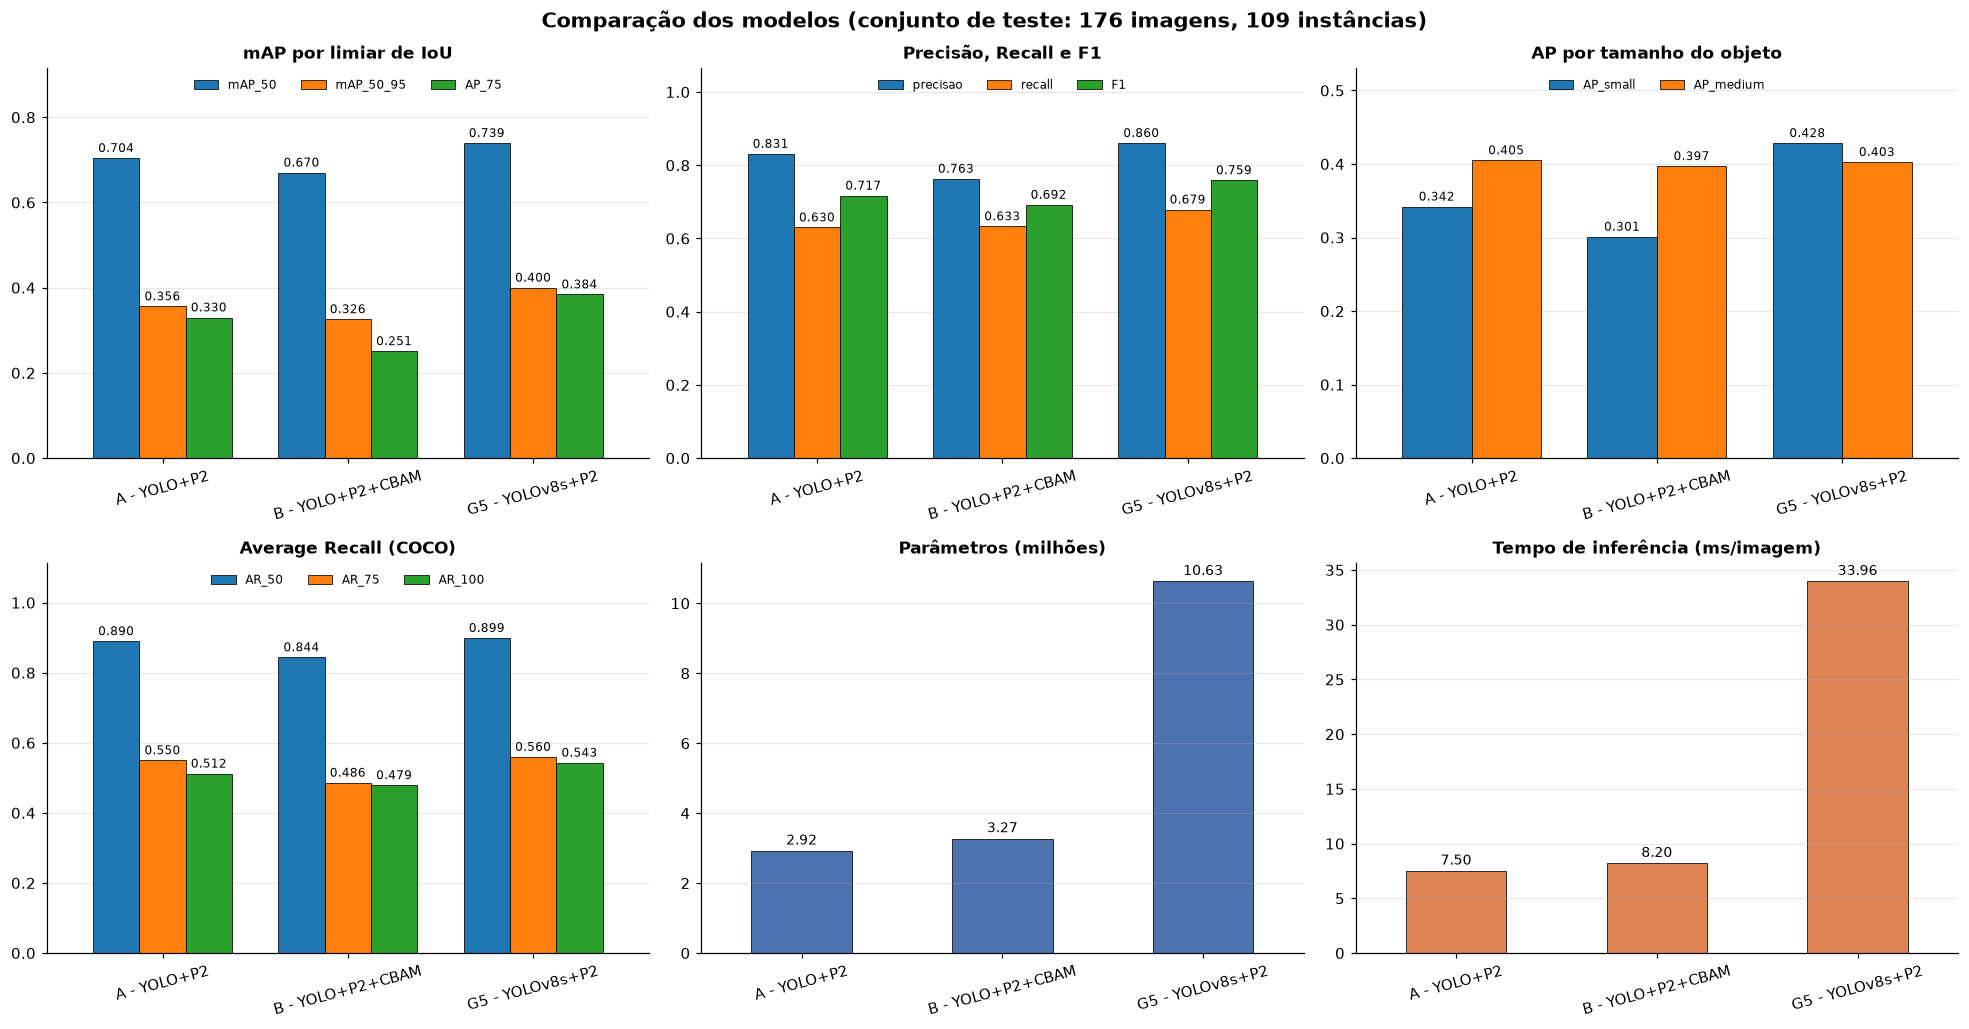

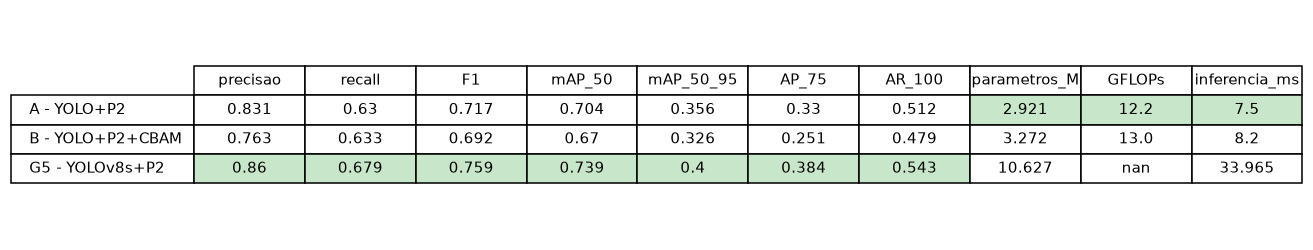

Arquivos salvos em: D:\testte\data-science-notebooks\MODELS\resultados


In [11]:
ordem = [NOME_A] + ([NOME_B] if INCLUIR_B else []) + [NOME_G5]
df = pd.DataFrame({n: resultados[n] for n in ordem}).T
df.index.name = "modelo"
for c in df.columns:
    df[c] = pd.to_numeric(df[c])

grupos = {
    "1_deteccao_mAP": ["mAP_50", "mAP_50_95", "AP_75", "AP_small", "AP_medium", "AP_large"],
    "2_precisao_recall": ["precisao", "recall", "F1"],
    "3_recall_COCO": ["AR_50", "AR_75", "AR_100", "AR_small", "AR_medium"],
    "4_eficiencia": ["parametros_M", "GFLOPs", "inferencia_ms"],
}
grupos = {k: [c for c in v if c in df.columns] for k, v in grupos.items()}
for nome, cols in grupos.items():
    df[cols].round(4).to_csv(SAIDA / f"{nome}_A_B_G5.csv")
try:
    with pd.ExcelWriter(SAIDA / "resultados_modelos_A_B_G5.xlsx") as xl:
        df.round(4).to_excel(xl, sheet_name="tudo")
        for nome, cols in grupos.items():
            df[cols].round(4).to_excel(xl, sheet_name=nome[:31])
except Exception as e:
    print("Excel não gerado (CSV foi salvo):", e)
print(df.round(3).T.to_string(), "\n")


def barras(ax, df, cols, titulo, ylabel=None):
    cols = [c for c in cols if c in df.columns]
    df[cols].plot(kind="bar", ax=ax, width=0.75, edgecolor="black", linewidth=0.5)
    ax.set_title(titulo, fontsize=11, fontweight="bold"); ax.set_xlabel("")
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=15); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_ylim(top=ax.get_ylim()[1] * 1.18)          # folga no topo para a legenda não cobrir rótulos
    ax.legend(fontsize=8, loc="upper center", ncol=len(cols), frameon=False)


plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fig, axs = plt.subplots(2, 3, figsize=(18, 9.5))
barras(axs[0, 0], df, ["mAP_50", "mAP_50_95", "AP_75"], "mAP por limiar de IoU")
barras(axs[0, 1], df, grupos["2_precisao_recall"], "Precisão, Recall e F1")
barras(axs[0, 2], df, [c for c in ["AP_small", "AP_medium"] if c in df], "AP por tamanho do objeto")
barras(axs[1, 0], df, ["AR_50", "AR_75", "AR_100"], "Average Recall (COCO)")
for ax, col, tit, cor in zip(axs[1, 1:], ["parametros_M", "inferencia_ms"],
                             ["Parâmetros (milhões)", "Tempo de inferência (ms/imagem)"], ["#4c72b0", "#dd8452"]):
    df[col].plot(kind="bar", ax=ax, color=cor, edgecolor="black", linewidth=0.5)
    ax.set_title(tit, fontsize=11, fontweight="bold"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
    ax.bar_label(ax.containers[0], fmt="%.2f", fontsize=9, padding=2); ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Comparação dos modelos (conjunto de teste: {int(df['imagens'].iloc[0])} imagens, "
             f"{int(df['instancias'].iloc[0])} instâncias)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(SAIDA / "dashboard_comparacao_A_B_G5.png", dpi=150)
plt.show()

# tabela-resumo como imagem (bom para slides); o melhor valor de cada coluna fica verde
resumo = df[[c for c in ["precisao", "recall", "F1", "mAP_50", "mAP_50_95", "AP_75", "AR_100", "parametros_M",
                         "GFLOPs", "inferencia_ms"] if c in df]].round(3)
fig, ax = plt.subplots(figsize=(13, 0.9 + 0.6 * len(resumo))); ax.axis("off")
tb = ax.table(cellText=resumo.values, rowLabels=resumo.index, colLabels=resumo.columns, loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(10); tb.scale(1, 1.6)
for j, col in enumerate(resumo.columns):
    melhor = resumo[col].idxmin() if col in ("parametros_M", "GFLOPs", "inferencia_ms") else resumo[col].idxmax()
    tb[list(resumo.index).index(melhor) + 1, j].set_facecolor("#c8e6c9")
plt.savefig(SAIDA / "tabela_resumo_A_B_G5.png", dpi=150, bbox_inches="tight")
plt.show()
print("Arquivos salvos em:", SAIDA.resolve())

## 6. Leitura rápida: G5 × A

In [12]:
a, g = df.loc[NOME_A], df.loc[NOME_G5]
print(f"{'métrica':14s} {'A':>8s} {'G5':>8s} {'G5 - A':>9s}")
for c in ["mAP_50", "mAP_50_95", "AP_75", "AP_small", "AP_medium", "precisao", "recall", "F1", "AR_50", "AR_75", "AR_100"]:
    print(f"{c:14s} {a[c]:8.3f} {g[c]:8.3f} {g[c] - a[c]:+9.3f}")
print(f"\nParâmetros: A {a['parametros_M']:.2f} M -> G5 {g['parametros_M']:.2f} M ({g['parametros_M'] / a['parametros_M']:.1f}x)")
print(f"Inferência: A {a['inferencia_ms']:.1f} ms -> G5 {g['inferencia_ms']:.1f} ms ({g['inferencia_ms'] / a['inferencia_ms']:.1f}x)")
print("\nObs.: com 109 objetos no teste, diferenças de poucos pontos (principalmente em AP_small/AR) estão dentro do ruído; "
      "o G5 usa 1024 px e o A 640 px, então o tempo de inferência não é diretamente comparável.")

métrica               A       G5    G5 - A
mAP_50            0.704    0.739    +0.035
mAP_50_95         0.356    0.400    +0.044
AP_75             0.330    0.384    +0.054
AP_small          0.342    0.428    +0.086
AP_medium         0.405    0.403    -0.002
precisao          0.831    0.860    +0.029
recall            0.630    0.679    +0.049
F1                0.717    0.759    +0.042
AR_50             0.890    0.899    +0.009
AR_75             0.550    0.560    +0.010
AR_100            0.512    0.543    +0.031

Parâmetros: A 2.92 M -> G5 10.63 M (3.6x)
Inferência: A 7.5 ms -> G5 34.0 ms (4.5x)

Obs.: com 109 objetos no teste, diferenças de poucos pontos (principalmente em AP_small/AR) estão dentro do ruído; o G5 usa 1024 px e o A 640 px, então o tempo de inferência não é diretamente comparável.
